This notebook attempts to break the recorded blooper signal down into simple components and then resynthesize a clean replacement signal.

In [1]:
%pylab inline
figsize(20,2)
import scipy.signal

Populating the interactive namespace from numpy and matplotlib


Let's take a look at the recorded blooper signal (after cropping off some silence at the beginning).

In [2]:
source_filename = 'bloop_f310500000_s4000000.cs8'
lo_freq = 310500000 # Hz
sample_rate = 4000000 # samples/sec

source_samples = (1/128)*np.fromfile(source_filename,dtype='int8').astype('float32').view('complex64')[19400:]
source_samples.shape, source_samples.dtype

((829990,), dtype('complex64'))

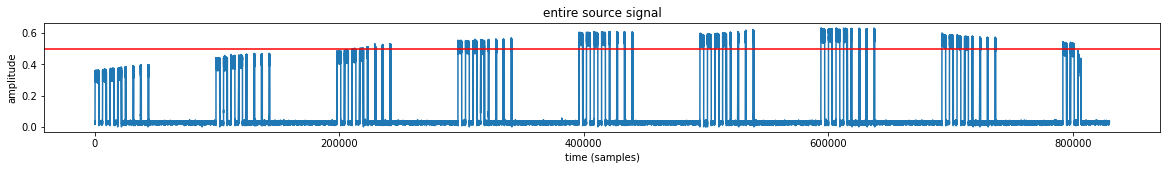

In [3]:
typical_amplitude = 0.5

plot(abs(source_samples));
title('entire source signal');
ylabel('amplitude');
xlabel('time (samples)');
axhline(typical_amplitude,color='red');

This looks line [on-off keying (OOK)](https://en.wikipedia.org/wiki/On%E2%80%93off_keying). There are burst and rest periods of equal length, and each burst conveys 8 symbols. Overall, the singal has ~8.5 bursts. From this, we can roughtly estimate a baud rate:

In [4]:
1/(len(source_samples)/(8.5*16)/sample_rate)

655.4295834889576

Let's zoom in on a single burst.

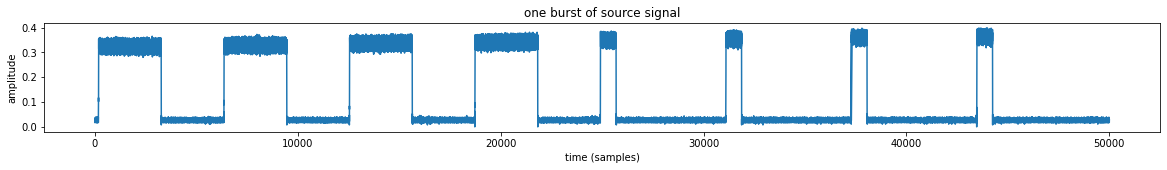

In [5]:
title('one burst of source signal');
ylabel('amplitude');
xlabel('time (samples)');
plot(abs(source_samples[:50000]));

Let's find the peak frequency for the entire signal (ignoring the DC signal). If we get a number higher than the Nyquist rate, we can interpret it as a wrapped negative frequency.

2598898.781913035

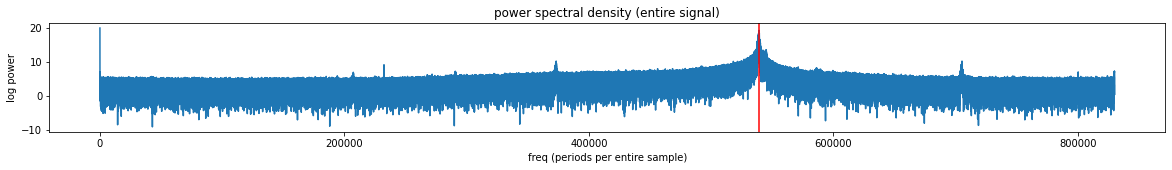

In [6]:
source_psd = abs(np.fft.fft(source_samples))**2
plot(log(source_psd))
title('power spectral density (entire signal)');
ylabel('log power');
xlabel('freq (periods per entire sample)');


peak_bin = argmax(source_psd*(arange(len(source_psd))>0))
axvline(peak_bin,color='red')
peak_freq = sample_rate*peak_bin/len(source_samples)
peak_freq

Now that we know the frequency of the carrier signal, let's try to more precisely recover the frequency of modulation (i.e. recover the symbol clock). We know there are between 8 and 9 bursts in the entire signal, so we'll mask out frequencies out of this range. It would be nice if I had a better peak finding method that could recover non-integer periodicities.

645.7909131435318

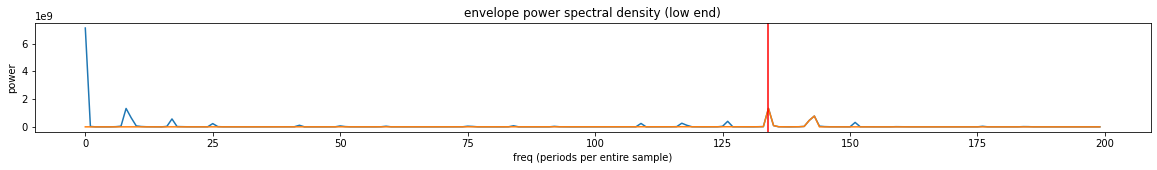

In [7]:
source_amp_psd = abs((np.fft.fft(abs(source_samples))[:200]))**2
plot(source_amp_psd)
bin_number = arange(len(source_amp_psd))
interesting_bin = np.logical_and(8*16 < bin_number, bin_number < 9*16)
plot(source_amp_psd*interesting_bin);
peak_amp_bin = argmax(source_amp_psd*interesting_bin)
axvline(peak_amp_bin,color='red');

title('envelope power spectral density (low end)');
ylabel('power');
xlabel('freq (periods per entire sample)');

clock_freq = sample_rate*peak_amp_bin/len(source_samples)
clock_freq

Let's generate an envelope pattern using the known 8-bit patter, the symbol clock rate, and the typical amplitue for "on" periods.

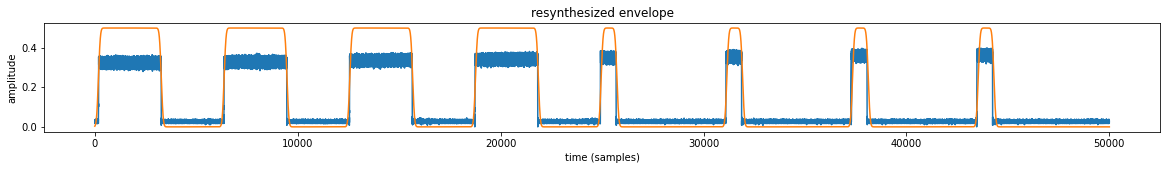

In [8]:
pattern = array([1,1,1,1,0,0,0,0])

symbol_clock = clock_freq*(-180+arange(len(source_samples)))/sample_rate

broadcasting = symbol_clock%(2*len(pattern)) < len(pattern)
symbol_index = (symbol_clock%len(pattern)).astype(int)

envelope = (symbol_clock%1 < where(pattern[symbol_index],0.5,0.125)) * broadcasting * typical_amplitude;

k = int(sample_rate/(clock_freq*10))
coef = np.exp(-linspace(-3,3,k)**2)
coef /= coef.sum()

envelope = scipy.signal.fftconvolve(envelope,coef,mode='same')
plot(abs(source_samples)[:50000]);
plot(envelope[:50000]);
title('resynthesized envelope');
ylabel('amplitude');
xlabel('time (samples)');

The envelope looks good, so let's use it to modulate a clean carrier signal.

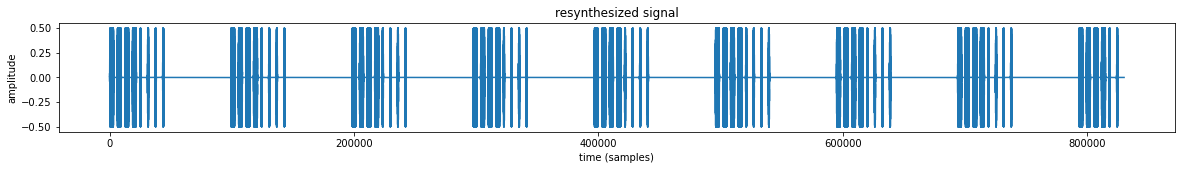

In [9]:
f = peak_freq
omega=f*(2*np.pi)/sample_rate
synth_samples = (exp(omega*1j*arange(len(source_samples)))*envelope).astype('complex64');
plot(synth_samples.real);
title('resynthesized signal');
ylabel('amplitude');
xlabel('time (samples)');

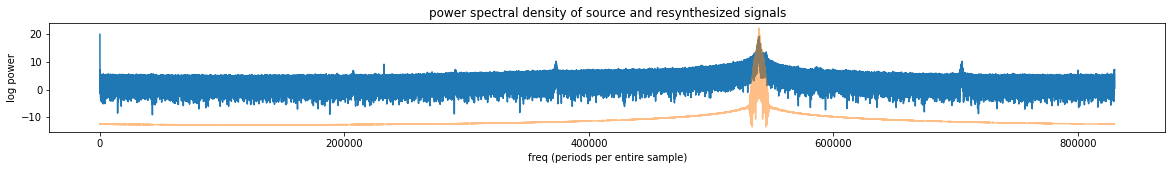

In [10]:
plot(log(abs(np.fft.fft(source_samples))**2))
plot(log(abs(np.fft.fft(synth_samples))**2),alpha=0.5)
title('power spectral density of source and resynthesized signals');
ylabel('log power');
xlabel('freq (periods per entire sample)');

The signal here is super clean! The particular shape of the off-peak details has some relation to the low-pass filter design that I don't understand, but I mostly care that it is much quieter than before. Let's slap on some dithering and save it out.

In [11]:
synth_filename = 'resynth_f310500000_s4000000.cs8'
((synth_samples*128).view('float32') + (np.random.random(2*len(synth_samples))-0.5)).astype('int8').tofile(synth_filename)

I was able to use this resynthesized signal to open the garage door!

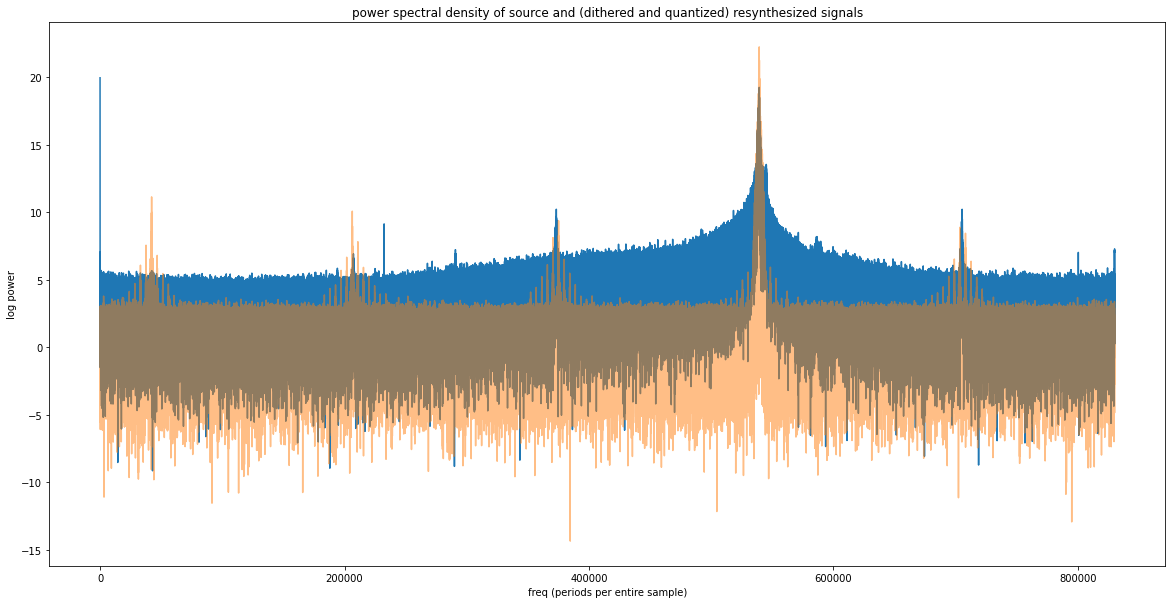

In [12]:
loaded_synth_samples = (1/128)*np.fromfile(synth_filename,dtype='int8').astype('float32').view('complex64')
figure(figsize=(20,10))
plot(log(abs(np.fft.fft(source_samples))**2))
plot(log(abs(np.fft.fft(loaded_synth_samples))**2),alpha=0.5)
title('power spectral density of source and (dithered and quantized) resynthesized signals');
ylabel('log power');
xlabel('freq (periods per entire sample)');